In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

DATA_PATH = Path("../data/raw/elia_raw_export.csv")
print("File exists:", DATA_PATH.exists())

# Semicolon-separated
df = pd.read_csv(DATA_PATH, sep=";")

print("\nRaw shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

File exists: True

Raw shape: (192665, 10)
Columns: ['Datetime', 'Resolution code', 'Total Load', 'Most recent forecast', 'Most recent P10', 'Most recent P90', 'Day-ahead 6PM forecast', 'Day-ahead 6PM P10', 'Day-ahead 6PM P90', 'Week-ahead forecast']

First 5 rows:


,Datetime,Resolution code,Total Load,Most recent forecast,Most recent P10,Most recent P90,Day-ahead 6PM forecast,Day-ahead 6PM P10,Day-ahead 6PM P90,Week-ahead forecast
0,2021-01-01T00:00:00+00:00,PT15M,8993.04,8638.49,8340.56,8936.42,8717.07,8419.14,9015.00,8562.61
1,2021-01-01T00:15:00+00:00,PT15M,8814.73,8558.46,8248.42,8868.49,8641.91,8346.55,8937.28,8490.09
2,2021-01-01T00:30:00+00:00,PT15M,8689.08,8461.72,8155.03,8768.41,8524.65,8233.29,8816.00,8376.77
3,2021-01-01T00:45:00+00:00,PT15M,8532.75,8360.79,8052.50,8669.09,8402.12,8110.10,8694.14,8276.24
4,2021-01-01T01:00:00+00:00,PT15M,8426.86,8228.99,7919.64,8538.35,8290.57,7997.53,8583.60,8184.62


In [2]:
# Parse Datetime column as proper datetime
df["Datetime"] = pd.to_datetime(df["Datetime"], utc=True)

# Set as index
df = df.set_index("Datetime").sort_index()

# Keep only Total Load (target) and ELIA's own forecasts (for later comparison)
cols_to_keep = ["Total Load", "Day-ahead 6PM forecast", "Most recent forecast"]
df = df[cols_to_keep].copy()

# Rename for easier handling
df.columns = ["totalload", "dayahead_forecast", "mostrecent_forecast"]

print("Shape after selection:", df.shape)
print(df.head())

Shape after selection: (192665, 3)
                           totalload  dayahead_forecast  mostrecent_forecast
Datetime                                                                    
2021-01-01 00:00:00+00:00    8993.04            8717.07              8638.49
2021-01-01 00:15:00+00:00    8814.73            8641.91              8558.46
2021-01-01 00:30:00+00:00    8689.08            8524.65              8461.72
2021-01-01 00:45:00+00:00    8532.75            8402.12              8360.79
2021-01-01 01:00:00+00:00    8426.86            8290.57              8228.99


In [3]:
print("Missing values before cleaning:")
print(df.isna().sum())

# Drop rows where target is missing
df = df.dropna(subset=["totalload"])

# Interpolate short gaps
df = df.interpolate(method="linear", limit=8)

print("\nMissing values after cleaning:")
print(df.isna().sum())
print("Shape:", df.shape)

Missing values before cleaning:
totalload              0
dayahead_forecast      0
mostrecent_forecast    0
dtype: int64

Missing values after cleaning:
totalload              0
dayahead_forecast      0
mostrecent_forecast    0
dtype: int64
Shape: (192665, 3)


In [4]:
df_hourly = df.resample("1h").mean().dropna()

print("Hourly shape:", df_hourly.shape)
print("Date range:", df_hourly.index.min(), "to", df_hourly.index.max())
display(df_hourly.head())

Hourly shape: (48167, 3)
Date range: 2021-01-01 00:00:00+00:00 to 2026-06-30 23:00:00+00:00


,totalload,dayahead_forecast,mostrecent_forecast
Datetime,,,
2021-01-01 00:00:00+00:00,8757.4000,8571.4375,8504.8650
2021-01-01 01:00:00+00:00,8263.4275,8160.9775,8091.2975
2021-01-01 02:00:00+00:00,7912.8275,7827.1225,7712.2600
2021-01-01 03:00:00+00:00,7765.5475,7628.6800,7545.5350
2021-01-01 04:00:00+00:00,7785.2850,7594.3100,7553.9200


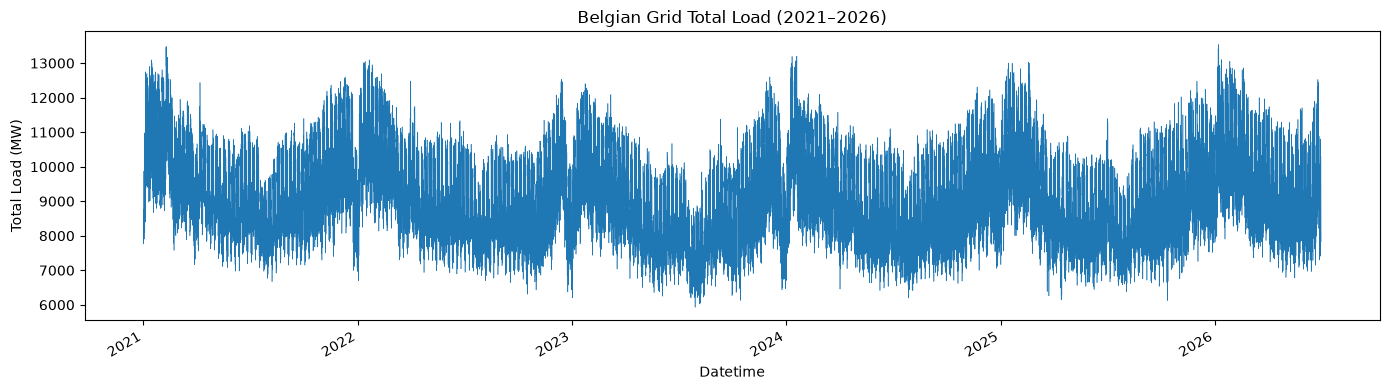

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
df_hourly["totalload"].plot(ax=ax, linewidth=0.4)
ax.set_title("Belgian Grid Total Load (2021–2026)")
ax.set_ylabel("Total Load (MW)")
plt.tight_layout()
plt.show()

In [6]:
df_hourly.to_csv("../data/processed/elia_hourly_load.csv")
print("Saved to data/processed/elia_hourly_load.csv")

Saved to data/processed/elia_hourly_load.csv


In [7]:
def create_windows(series, window_size=24, horizon=1):
    X, y = [], []
    values = series.values
    for i in range(len(values) - window_size - horizon + 1):
        X.append(values[i : i + window_size])
        y.append(values[i + window_size + horizon - 1])
    return np.array(X), np.array(y)

target = df_hourly["totalload"]
X, y = create_windows(target, window_size=24, horizon=1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (48143, 24)
y shape: (48143,)


In [8]:
n = len(X)
train_end = int(0.70 * n)
val_end   = int(0.85 * n)

X_train, y_train = X[:train_end], y[:train_end]
X_val,   y_val   = X[train_end:val_end], y[train_end:val_end]
X_test,  y_test  = X[val_end:], y[val_end:]

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (33700, 24), Val: (7221, 24), Test: (7222, 24)


In [9]:
scaler_elia = MinMaxScaler()
X_train_s = scaler_elia.fit_transform(X_train)
X_val_s   = scaler_elia.transform(X_val)
X_test_s  = scaler_elia.transform(X_test)

joblib.dump(scaler_elia, "../models/elia_scaler.pkl")
print("Scaler saved to models/elia_scaler.pkl")

Scaler saved to models/elia_scaler.pkl


In [10]:
np.save("../data/processed/elia_X_train.npy", X_train_s)
np.save("../data/processed/elia_y_train.npy", y_train)
np.save("../data/processed/elia_X_val.npy", X_val_s)
np.save("../data/processed/elia_y_val.npy", y_val)
np.save("../data/processed/elia_X_test.npy", X_test_s)
np.save("../data/processed/elia_y_test.npy", y_test)
print("All ELIA splits saved to data/processed/")

All ELIA splits saved to data/processed/
